# 08 — GRU: a recurrent neural network comparison

The reference paper suggests a recurrent neural network as a natural comparison for the tree, kernel and feed-forward models. This notebook trains a **GRU (Gated Recurrent Unit)** on the same processed datasets, split and feature sets as Notebooks 03 and 04, for both tasks:

- **Classification:** next-observation direction, compared with the majority-class baseline and the saved Random Forest / SVM-RBF test results.
- **Regression:** next-observation log return, compared with the mean-return baseline and the saved regression test results.

**How the GRU differs from the earlier models.** Random Forest, SVM and MLP see one row of features per forecast. The GRU sees a *sequence*: the feature rows for the last `SEQ_LEN` observations ending on the forecast date, so it can learn from how the features evolved over that window.

**Protocol (same as Notebooks 03–04).**
- Chronological 80/10/10 split; features are standardised with statistics from the training rows only.
- Validation is used to choose the feature set and the number of training epochs (early stopping on validation loss). Because validation also stops training, validation scores are slightly optimistic; the test set is the honest estimate.
- The chosen configuration is retrained on train + validation for the epoch count found on validation, then evaluated once on test.
- An input window may reach back into an earlier split. Those observations were known on the forecast date, so no future information is used.

Run Notebooks 02, 03 and 04 first so the processed datasets and comparison results exist.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, balanced_accuracy_score, r2_score, mean_squared_error

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from fx_utils import PAIRS, PROCESSED_DIR, RESULTS_DIR, chronological_split, get_feature_sets

data = {
    pair: pd.read_csv(PROCESSED_DIR / f"{pair}_model_data.csv", index_col=0, parse_dates=True)
    for pair in PAIRS
}
splits = {pair: chronological_split(data[pair]) for pair in PAIRS}

SEQ_LEN = 20        # observations per input sequence (about one month of weekdays)
HIDDEN_SIZE = 32
DROPOUT = 0.2
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
BATCH_SIZE = 64
MAX_EPOCHS = 30
PATIENCE = 5        # stop after this many epochs without a lower validation loss
SEED = 42

TASKS = {"classification": "target_direction", "regression": "target_return"}

# A model this small trains fastest on a few threads; more mostly adds overhead and memory.
torch.set_num_threads(4)

print("PyTorch", torch.__version__)
for pair in PAIRS:
    print(pair, {name: len(part) for name, part in splits[pair].items()})

PyTorch 2.6.0+cpu
GBP_USD {'train': 4423, 'val': 553, 'test': 553}
USD_EUR {'train': 4423, 'val': 553, 'test': 553}
USD_JPY {'train': 4423, 'val': 553, 'test': 553}


## 1. Sequences, model and training loop

In [2]:
def make_sequences(pair, rows, cols, target_col, scaler):
    # One window per row in `rows`: the SEQ_LEN standardised feature rows ending on that date.
    full = data[pair]
    X_all = scaler.transform(full[cols]).astype(np.float32)
    positions = full.index.get_indexer(rows.index)
    positions = positions[positions >= SEQ_LEN - 1]
    X = np.stack([X_all[i - SEQ_LEN + 1:i + 1] for i in positions])
    y = full[target_col].to_numpy(dtype=np.float32)[positions]
    return torch.from_numpy(X), y


class GRUNet(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.gru = nn.GRU(n_features, HIDDEN_SIZE, batch_first=True)
        self.dropout = nn.Dropout(DROPOUT)
        self.head = nn.Linear(HIDDEN_SIZE, 1)

    def forward(self, x):
        _, hidden = self.gru(x)          # final hidden state summarises the whole window
        return self.head(self.dropout(hidden[-1])).squeeze(-1)


def fit_gru(X_train, y_train, task, epochs, X_val=None, y_val=None):
    # With validation data: early-stop and return the best epoch's weights.
    # Without: train for exactly `epochs` epochs (used for the final refit).
    torch.manual_seed(SEED)
    model = GRUNet(X_train.shape[2])
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    loss_fn = nn.BCEWithLogitsLoss() if task == "classification" else nn.MSELoss()
    loader = DataLoader(
        TensorDataset(X_train, torch.tensor(y_train, dtype=torch.float32)),
        batch_size=BATCH_SIZE, shuffle=True
    )

    best_loss, best_epoch, best_state, waited = np.inf, epochs, None, 0
    for epoch in range(1, epochs + 1):
        model.train()
        for xb, yb in loader:
            optimizer.zero_grad()
            loss_fn(model(xb), yb).backward()
            optimizer.step()
        if X_val is None:
            continue
        model.eval()
        with torch.no_grad():
            val_loss = loss_fn(model(X_val), torch.tensor(y_val, dtype=torch.float32)).item()
        if val_loss < best_loss:
            best_loss, best_epoch, waited = val_loss, epoch, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            waited += 1
            if waited >= PATIENCE:
                break
    if best_state is not None:
        model.load_state_dict(best_state)
    return model, best_epoch


def predict(model, X, task):
    model.eval()
    with torch.no_grad():
        output = model(X).numpy()
    return (output > 0).astype(int) if task == "classification" else output


def rmse(actual, pred):
    return np.sqrt(mean_squared_error(actual, pred))


def fit_and_score(pair, fit_rows, eval_rows, cols, task, epochs, early_stop):
    # Shared by validation (early_stop=True) and the final test refit (early_stop=False).
    target_col = f"{pair}_{TASKS[task]}"
    scaler = StandardScaler().fit(fit_rows[cols])
    X_fit, y_fit = make_sequences(pair, fit_rows, cols, target_col, scaler)
    X_eval, y_eval = make_sequences(pair, eval_rows, cols, target_col, scaler)

    if task == "classification":
        model, best_epoch = fit_gru(X_fit, y_fit, task, epochs,
                                    *((X_eval, y_eval) if early_stop else ()))
        pred = predict(model, X_eval, task)
        majority = int(fit_rows[target_col].mode()[0])
        return best_epoch, y_eval.astype(int), pred, np.full(len(y_eval), majority)

    # Standardise the regression target: daily log returns are ~0.004, which would
    # otherwise leave the loss and gradients tiny relative to the weight decay.
    mean, std = fit_rows[target_col].mean(), fit_rows[target_col].std()
    model, best_epoch = fit_gru(X_fit, (y_fit - mean) / std, task, epochs,
                                *((X_eval, (y_eval - mean) / std) if early_stop else ()))
    pred = predict(model, X_eval, task) * std + mean
    return best_epoch, y_eval, pred, np.full(len(y_eval), mean)

## 2. Validation: compare feature sets and find the epoch count

3 currency pairs × 3 feature sets × 2 tasks. The test set is not touched here.

In [3]:
validation_rows = []
best_epochs = {}

for pair in PAIRS:
    train, val = splits[pair]["train"], splits[pair]["val"]
    for feature_set, cols in get_feature_sets(pair).items():
        for task in TASKS:
            best_epoch, y_val, pred, base = fit_and_score(
                pair, train, val, cols, task, MAX_EPOCHS, early_stop=True
            )
            best_epochs[(pair, feature_set, task)] = best_epoch
            row = {"Task": task, "Currency Pair": pair, "Model": "GRU",
                   "Features": feature_set, "Best Epoch": best_epoch}
            if task == "classification":
                row.update({"Validation Accuracy": accuracy_score(y_val, pred),
                            "Balanced Accuracy": balanced_accuracy_score(y_val, pred)})
            else:
                row.update({"Validation R²": r2_score(y_val, pred), "Validation RMSE": rmse(y_val, pred),
                            "Baseline R²": r2_score(y_val, base), "Baseline RMSE": rmse(y_val, base)})
            validation_rows.append(row)

gru_validation = pd.DataFrame(validation_rows)
gru_class_val = gru_validation[gru_validation["Task"] == "classification"].dropna(axis=1)
gru_reg_val = gru_validation[gru_validation["Task"] == "regression"].dropna(axis=1)
display(gru_class_val.round(4))
display(gru_reg_val.round(6))

,Task,Currency Pair,Model,Features,Best Epoch,Validation Accuracy,Balanced Accuracy
0,classification,GBP_USD,GRU,7,11,0.4901,0.4932
2,classification,GBP_USD,GRU,15-paper,2,0.5280,0.5042
4,classification,GBP_USD,GRU,15-stationary,1,0.5298,0.5287
6,classification,USD_EUR,GRU,7,1,0.5190,0.5079
8,classification,USD_EUR,GRU,15-paper,1,0.5154,0.5006
10,classification,USD_EUR,GRU,15-stationary,3,0.5208,0.5118
12,classification,USD_JPY,GRU,7,2,0.5515,0.5216
14,classification,USD_JPY,GRU,15-paper,5,0.5823,0.5187
16,classification,USD_JPY,GRU,15-stationary,1,0.5588,0.5235


,Task,Currency Pair,Model,Features,Best Epoch,Validation R²,Validation RMSE,Baseline R²,Baseline RMSE
1,regression,GBP_USD,GRU,7,6,-0.006165,0.005961,-0.002384,0.005950
3,regression,GBP_USD,GRU,15-paper,1,-0.002512,0.005950,-0.002384,0.005950
5,regression,GBP_USD,GRU,15-stationary,1,0.004752,0.005928,-0.002384,0.005950
7,regression,USD_EUR,GRU,7,9,-0.000599,0.004903,-0.002347,0.004908
9,regression,USD_EUR,GRU,15-paper,10,0.000004,0.004902,-0.002347,0.004908
11,regression,USD_EUR,GRU,15-stationary,1,-0.001381,0.004905,-0.002347,0.004908
13,regression,USD_JPY,GRU,7,1,-0.006166,0.007023,-0.000009,0.007001
15,regression,USD_JPY,GRU,15-paper,4,-0.010492,0.007038,-0.000009,0.007001
17,regression,USD_JPY,GRU,15-stationary,1,0.000397,0.007000,-0.000009,0.007001


In [4]:
# Choose one feature set per task from validation only, using the same rules as
# Notebooks 03 (mean balanced accuracy) and 04 (mean RMSE relative to the baseline).
class_choice = gru_class_val.groupby("Features")["Balanced Accuracy"].mean().idxmax()
reg_ratio = gru_reg_val["Validation RMSE"] / gru_reg_val["Baseline RMSE"]
reg_choice = reg_ratio.groupby(gru_reg_val["Features"]).mean().idxmin()

display(gru_class_val.groupby("Features")[["Validation Accuracy", "Balanced Accuracy"]].mean().round(4))
display(reg_ratio.groupby(gru_reg_val["Features"]).mean().rename("Mean RMSE / baseline RMSE").round(4).to_frame())
print("Chosen on validation — classification:", class_choice, "| regression:", reg_choice)

,Validation Accuracy,Balanced Accuracy
Features,,
15-paper,0.5419,0.5078
15-stationary,0.5365,0.5213
7,0.5202,0.5076


,Mean RMSE / baseline RMSE
Features,
15-paper,1.0014
15-stationary,0.9986
7,1.0014


Chosen on validation — classification: 15-stationary | regression: 15-stationary


## 3. Final test: retrain on train + validation, evaluate once

In [5]:
class_test_rows, reg_test_rows = [], []

for pair in PAIRS:
    train, val, test = splits[pair]["train"], splits[pair]["val"], splits[pair]["test"]
    development = pd.concat([train, val])

    cols = get_feature_sets(pair)[class_choice]
    epochs = best_epochs[(pair, class_choice, "classification")]
    _, y_test, pred, _ = fit_and_score(pair, development, test, cols, "classification", epochs, early_stop=False)
    class_test_rows.append({
        "Currency Pair": pair, "Model": "GRU", "Features": class_choice,
        "Test Accuracy": accuracy_score(y_test, pred),
        "Test Balanced Accuracy": balanced_accuracy_score(y_test, pred)
    })

    cols = get_feature_sets(pair)[reg_choice]
    epochs = best_epochs[(pair, reg_choice, "regression")]
    _, y_test, pred, base = fit_and_score(pair, development, test, cols, "regression", epochs, early_stop=False)
    reg_test_rows.append({
        "Currency Pair": pair, "Model": "GRU", "Features": reg_choice,
        "Test R²": r2_score(y_test, pred), "Test RMSE": rmse(y_test, pred),
        "Baseline R²": r2_score(y_test, base), "Baseline RMSE": rmse(y_test, base)
    })

gru_class_test = pd.DataFrame(class_test_rows)
gru_reg_test = pd.DataFrame(reg_test_rows)
display(gru_class_test.round(4))
display(gru_reg_test.round(6))

,Currency Pair,Model,Features,Test Accuracy,Test Balanced Accuracy
0,GBP_USD,GRU,15-stationary,0.4521,0.4546
1,USD_EUR,GRU,15-stationary,0.4991,0.5012
2,USD_JPY,GRU,15-stationary,0.5262,0.4904


,Currency Pair,Model,Features,Test R²,Test RMSE,Baseline R²,Baseline RMSE
0,GBP_USD,GRU,15-stationary,0.000799,0.004469,-0.000183,0.004471
1,USD_EUR,GRU,15-stationary,-0.004363,0.004344,-0.000046,0.004335
2,USD_JPY,GRU,15-stationary,-0.007333,0.005922,-0.000378,0.005902


## 4. Compare with the baselines and the earlier models

The Random Forest, SVM-RBF and SVR rows come from the saved results of Notebooks 03 and 04, which were evaluated on the same test observations.

In [6]:
earlier_class = pd.read_csv(RESULTS_DIR / "classification_test_results.csv")
earlier_reg = pd.read_csv(RESULTS_DIR / "regression_test_results.csv")

class_comparison = pd.concat([earlier_class, gru_class_test], ignore_index=True)
reg_comparison = pd.concat([earlier_reg, gru_reg_test], ignore_index=True)

print("Classification — test accuracy")
display(class_comparison.pivot(index="Currency Pair", columns="Model", values="Test Accuracy").round(4))
print("Classification — test balanced accuracy")
display(class_comparison.pivot(index="Currency Pair", columns="Model", values="Test Balanced Accuracy").round(4))

print("Regression — test RMSE (lower is better) and R²")
display(reg_comparison[["Currency Pair", "Model", "Features", "Test R²", "Test RMSE",
                        "Baseline RMSE"]].round(6))

Classification — test accuracy


Model,GRU,Majority baseline,Random Forest,SVM-RBF
Currency Pair,,,,
GBP_USD,0.4521,0.5045,0.5244,0.5118
USD_EUR,0.4991,0.4756,0.5262,0.5099
USD_JPY,0.5262,0.5570,0.5118,0.5353


Classification — test balanced accuracy


Model,GRU,Majority baseline,Random Forest,SVM-RBF
Currency Pair,,,,
GBP_USD,0.4546,0.5,0.5254,0.5133
USD_EUR,0.5012,0.5,0.5309,0.5223
USD_JPY,0.4904,0.5,0.4953,0.4843


Regression — test RMSE (lower is better) and R²


,Currency Pair,Model,Features,Test R²,Test RMSE,Baseline RMSE
0,GBP_USD,SVR-RBF,15-paper,0.010626,0.004447,0.004471
1,USD_EUR,SVR-RBF,15-paper,-0.022399,0.004383,0.004335
2,USD_JPY,SVR-RBF,15-paper,-0.079367,0.006130,0.005902
3,GBP_USD,GRU,15-stationary,0.000799,0.004469,0.004471
4,USD_EUR,GRU,15-stationary,-0.004363,0.004344,0.004335
5,USD_JPY,GRU,15-stationary,-0.007333,0.005922,0.005902


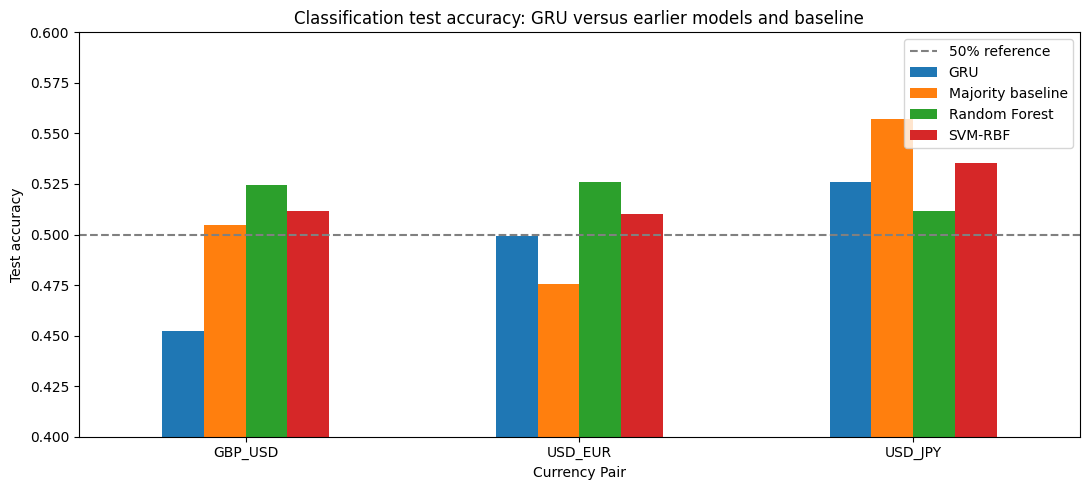

In [7]:
accuracy_table = class_comparison.pivot(index="Currency Pair", columns="Model", values="Test Accuracy")
ax = accuracy_table.plot(kind="bar", figsize=(11, 5), rot=0)
ax.axhline(0.5, linestyle="--", color="grey", label="50% reference")
ax.set_ylabel("Test accuracy")
ax.set_ylim(0.4, 0.6)
ax.set_title("Classification test accuracy: GRU versus earlier models and baseline")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

In [8]:
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
gru_validation.to_csv(RESULTS_DIR / "gru_validation_results.csv", index=False)
pd.concat([gru_class_test.assign(Task="classification"), gru_reg_test.assign(Task="regression")],
          ignore_index=True).to_csv(RESULTS_DIR / "gru_test_results.csv", index=False)
print("Saved GRU result tables to", RESULTS_DIR)

Saved GRU result tables to D:\NeuDocuments\SideProject\MiniProject\ML\Foreign-exchange-forecast\results


## Interpretation

- Compare the GRU with the **baseline first**, then with the earlier models. Beating Random Forest but not the majority class still means no useful directional signal.
- Daily FX returns have almost no serial correlation, so a sequence model is not expected to do much better than the single-row models; a result close to the baselines is a valid finding, not a failure of the notebook.
- A best epoch of 1–3 on validation means the network starts fitting noise almost immediately: there is little stable pattern for it to learn.
- Results depend on the random seed and on the fixed settings above (`SEQ_LEN`, `HIDDEN_SIZE`, `DROPOUT`). Any tuning of these must use validation results only.